In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Data Preview

In [69]:
# read the covid data 
df = pd.read_csv("covid_19_data.csv")
df.head()

,SNo,ObservationDate,Province/State,Country/Region,Last Update,Confirmed,Deaths,Recovered
0,1,01/22/2020,Anhui,Mainland China,1/22/2020 17:00,1.0,0.0,0.0
1,2,01/22/2020,Beijing,Mainland China,1/22/2020 17:00,14.0,0.0,0.0
2,3,01/22/2020,Chongqing,Mainland China,1/22/2020 17:00,6.0,0.0,0.0
3,4,01/22/2020,Fujian,Mainland China,1/22/2020 17:00,1.0,0.0,0.0
4,5,01/22/2020,Gansu,Mainland China,1/22/2020 17:00,0.0,0.0,0.0


In [3]:
# check the basic stats and information for the data
df.describe()

,SNo,Confirmed,Deaths,Recovered
count,306429.000000,3.064290e+05,306429.000000,3.064290e+05
mean,153215.000000,8.567091e+04,2036.403268,5.042029e+04
std,88458.577156,2.775516e+05,6410.938048,2.015124e+05
min,1.000000,-3.028440e+05,-178.000000,-8.544050e+05
25%,76608.000000,1.042000e+03,13.000000,1.100000e+01
50%,153215.000000,1.037500e+04,192.000000,1.751000e+03
75%,229822.000000,5.075200e+04,1322.000000,2.027000e+04
max,306429.000000,5.863138e+06,112385.000000,6.399531e+06


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 306429 entries, 0 to 306428
Data columns (total 8 columns):
 #   Column           Non-Null Count   Dtype  
---  ------           --------------   -----  
 0   SNo              306429 non-null  int64  
 1   ObservationDate  306429 non-null  object 
 2   Province/State   228329 non-null  object 
 3   Country/Region   306429 non-null  object 
 4   Last Update      306429 non-null  object 
 5   Confirmed        306429 non-null  float64
 6   Deaths           306429 non-null  float64
 7   Recovered        306429 non-null  float64
dtypes: float64(3), int64(1), object(4)
memory usage: 18.7+ MB


In [6]:
# simple check: any duplicates? missing? outliers? 
df['SNo'].unique()

array([     1,      2,      3, ..., 306427, 306428, 306429], dtype=int64)

In [8]:
df[df.duplicated()]

,SNo,ObservationDate,Province/State,Country/Region,Last Update,Confirmed,Deaths,Recovered


In [9]:
df.duplicated().sum()

0

In [11]:
# missing data
df.isnull().sum()

SNo                    0
ObservationDate        0
Province/State     78100
Country/Region         0
Last Update            0
Confirmed              0
Deaths                 0
Recovered              0
dtype: int64

In [13]:
df[df['Province/State'].isnull()]

,SNo,ObservationDate,Province/State,Country/Region,Last Update,Confirmed,Deaths,Recovered
35,36,01/22/2020,NaN,Japan,1/22/2020 17:00,2.0,0.0,0.0
36,37,01/22/2020,NaN,Thailand,1/22/2020 17:00,4.0,0.0,2.0
37,38,01/22/2020,NaN,South Korea,1/22/2020 17:00,1.0,0.0,0.0
39,40,01/22/2020,NaN,Kiribati,1/22/2020 17:00,0.0,0.0,0.0
75,76,01/23/2020,NaN,Japan,1/23/20 17:00,1.0,0.0,0.0
...,...,...,...,...,...,...,...,...
305831,305832,05/29/2021,NaN,Vietnam,2021-05-30 04:20:55,6908.0,47.0,2896.0
305832,305833,05/29/2021,NaN,West Bank and Gaza,2021-05-30 04:20:55,307838.0,3492.0,300524.0
305833,305834,05/29/2021,NaN,Yemen,2021-05-30 04:20:55,6731.0,1319.0,3399.0
305834,305835,05/29/2021,NaN,Zambia,2021-05-30 04:20:55,94751.0,1276.0,91594.0


In [14]:
78100/306429 # drop/ remove them or fillna? 

0.25487143840824467

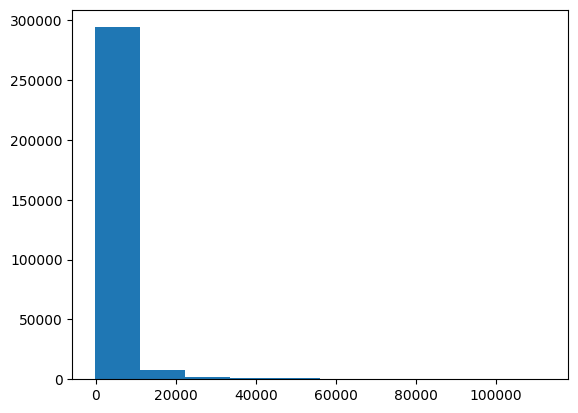

In [20]:
# outliers: 
## plotting check outliers ## 
### histogram 
plt.hist(df['Deaths'])
#plt.xlim(0,60000)
plt.show()

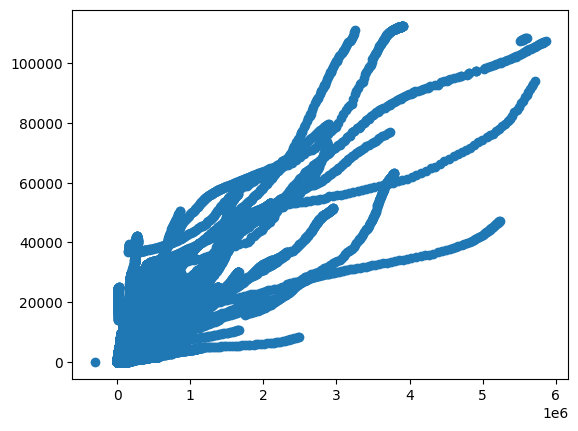

In [22]:
### scatter plot
plt.scatter(df['Confirmed'], df['Deaths']);

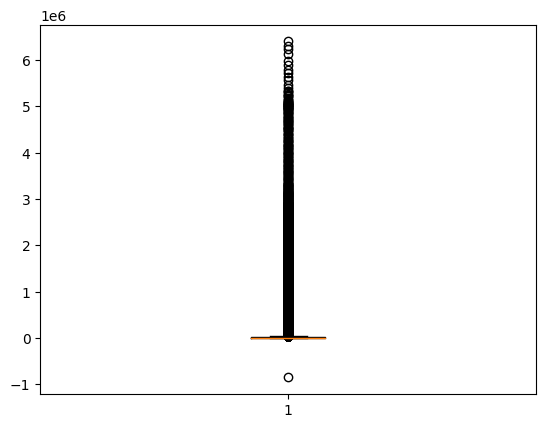

In [25]:
### box plot
plt.boxplot(df['Recovered']);

In [ ]:
### other outlier check techniques: show later 
### 1. using stats techniques: 1.5 IQR or 95% CI  
### 2. advanced outlier algorithms (auto checking outliers)

# Data Prepration and Transformation

In [27]:
df

,SNo,ObservationDate,Province/State,Country/Region,Last Update,Confirmed,Deaths,Recovered
0,1,01/22/2020,Anhui,Mainland China,1/22/2020 17:00,1.0,0.0,0.0
1,2,01/22/2020,Beijing,Mainland China,1/22/2020 17:00,14.0,0.0,0.0
2,3,01/22/2020,Chongqing,Mainland China,1/22/2020 17:00,6.0,0.0,0.0
3,4,01/22/2020,Fujian,Mainland China,1/22/2020 17:00,1.0,0.0,0.0
4,5,01/22/2020,Gansu,Mainland China,1/22/2020 17:00,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...
306424,306425,05/29/2021,Zaporizhia Oblast,Ukraine,2021-05-30 04:20:55,102641.0,2335.0,95289.0
306425,306426,05/29/2021,Zeeland,Netherlands,2021-05-30 04:20:55,29147.0,245.0,0.0
306426,306427,05/29/2021,Zhejiang,Mainland China,2021-05-30 04:20:55,1364.0,1.0,1324.0
306427,306428,05/29/2021,Zhytomyr Oblast,Ukraine,2021-05-30 04:20:55,87550.0,1738.0,83790.0


In [70]:
## if we directly drop null data 
clean_df = df.dropna(axis=0, how='any') # any, all, threshold

In [65]:
clean_df.isnull().sum()

SNo                0
ObservationDate    0
Province/State     0
Country/Region     0
Last Update        0
Confirmed          0
Deaths             0
Recovered          0
dtype: int64

In [32]:
clean_df

,SNo,ObservationDate,Province/State,Country/Region,Last Update,Confirmed,Deaths,Recovered
0,1,01/22/2020,Anhui,Mainland China,1/22/2020 17:00,1.0,0.0,0.0
1,2,01/22/2020,Beijing,Mainland China,1/22/2020 17:00,14.0,0.0,0.0
2,3,01/22/2020,Chongqing,Mainland China,1/22/2020 17:00,6.0,0.0,0.0
3,4,01/22/2020,Fujian,Mainland China,1/22/2020 17:00,1.0,0.0,0.0
4,5,01/22/2020,Gansu,Mainland China,1/22/2020 17:00,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...
306424,306425,05/29/2021,Zaporizhia Oblast,Ukraine,2021-05-30 04:20:55,102641.0,2335.0,95289.0
306425,306426,05/29/2021,Zeeland,Netherlands,2021-05-30 04:20:55,29147.0,245.0,0.0
306426,306427,05/29/2021,Zhejiang,Mainland China,2021-05-30 04:20:55,1364.0,1.0,1324.0
306427,306428,05/29/2021,Zhytomyr Oblast,Ukraine,2021-05-30 04:20:55,87550.0,1738.0,83790.0


In [34]:
## pick features you need only or try to use feature engineering (next time)
## drop columns or using slices 
cols = clean_df.columns
cols

Index(['SNo', 'ObservationDate', 'Province/State', 'Country/Region',
       'Last Update', 'Confirmed', 'Deaths', 'Recovered'],
      dtype='object')

In [71]:
pick_df = clean_df[['Province/State', 'Country/Region', 'Confirmed', 'Deaths', 'Recovered']]
pick_df

,Province/State,Country/Region,Confirmed,Deaths,Recovered
0,Anhui,Mainland China,1.0,0.0,0.0
1,Beijing,Mainland China,14.0,0.0,0.0
2,Chongqing,Mainland China,6.0,0.0,0.0
3,Fujian,Mainland China,1.0,0.0,0.0
4,Gansu,Mainland China,0.0,0.0,0.0
...,...,...,...,...,...
306424,Zaporizhia Oblast,Ukraine,102641.0,2335.0,95289.0
306425,Zeeland,Netherlands,29147.0,245.0,0.0
306426,Zhejiang,Mainland China,1364.0,1.0,1324.0
306427,Zhytomyr Oblast,Ukraine,87550.0,1738.0,83790.0


In [37]:
## transform data, make sure x (features) and y (prediction)
### non-numeric categorical data and numeric data
#### check non-numeric first
pick_df['Province/State'].unique()

array(['Anhui', 'Beijing', 'Chongqing', 'Fujian', 'Gansu', 'Guangdong',
       'Guangxi', 'Guizhou', 'Hainan', 'Hebei', 'Heilongjiang', 'Henan',
       'Hong Kong', 'Hubei', 'Hunan', 'Inner Mongolia', 'Jiangsu',
       'Jiangxi', 'Jilin', 'Liaoning', 'Macau', 'Ningxia', 'Qinghai',
       'Shaanxi', 'Shandong', 'Shanghai', 'Shanxi', 'Sichuan', 'Taiwan',
       'Tianjin', 'Tibet', 'Washington', 'Xinjiang', 'Yunnan', 'Zhejiang',
       'Unknown', 'Chicago', 'Illinois', 'California', 'Arizona',
       'Ontario', 'New South Wales', 'Victoria', 'British Columbia',
       'Bavaria', 'Queensland', 'Chicago, IL', 'South Australia',
       'Boston, MA', 'Los Angeles, CA', 'Orange, CA', 'Santa Clara, CA',
       'Seattle, WA', 'Tempe, AZ', 'San Benito, CA', 'Toronto, ON',
       'London, ON', 'Madison, WI', 'Cruise Ship',
       'Diamond Princess cruise ship', 'San Diego County, CA',
       'San Antonio, TX', 'Ashland, NE', 'Travis, CA',
       'From Diamond Princess', 'Lackland, TX', 'None',
   

In [39]:
len(pick_df['Province/State'].unique())

737

In [41]:
len(pick_df['Country/Region'].unique())

32

In [55]:
pick_df['Country/Region'].unique()

array(['Mainland China', 'Hong Kong', 'Macau', 'Taiwan', 'US', 'China',
       'Canada', 'Australia', 'Germany', 'Others', 'Israel', 'Lebanon',
       'Iraq', 'Austria', 'France', 'UK', 'Denmark', 'Netherlands',
       'Italy', 'Spain', 'Brazil', 'Mexico', 'Chile', 'Japan', 'Colombia',
       'Peru', 'Russia', 'Ukraine', 'Sweden', 'India', 'Pakistan',
       'Belgium'], dtype=object)

In [74]:
## simple tranform non-numerical => into numeric: assign categorical data into numbers       

In [ ]:
# standardization or normlization

# Filling NA

In [77]:
data = pd.DataFrame([[1,2,3], [np.nan,np.nan,2], [3,4,np.nan]])
data

,0,1,2
0,1.0,2.0,3.0
1,NaN,NaN,2.0
2,3.0,4.0,NaN


In [78]:
# fill na in common label or numbers 
data.fillna(10) # check inplace 

,0,1,2
0,1.0,2.0,3.0
1,10.0,10.0,2.0
2,3.0,4.0,10.0


In [80]:
# fill specific numbers by dictionary
data.fillna({0:10, 1:20, 2:30})

,0,1,2
0,1.0,2.0,3.0
1,10.0,20.0,2.0
2,3.0,4.0,30.0


In [81]:
# fill na using the forward(previous value)
data.fillna(method='ffill')

,0,1,2
0,1.0,2.0,3.0
1,1.0,2.0,2.0
2,3.0,4.0,2.0


In [82]:
# fill na using the backward
data.fillna(method='bfill') # axis and limit

,0,1,2
0,1.0,2.0,3.0
1,3.0,4.0,2.0
2,3.0,4.0,NaN


In [ ]:
# fill na by mean 

In [89]:
data.iloc[:,0]

0    1.0
1    NaN
2    3.0
Name: 0, dtype: float64

In [90]:
data.iloc[:,0].mean()

2.0

In [88]:
data.fillna(data.iloc[:,0].mean())

,0,1,2
0,1.0,2.0,3.0
1,2.0,2.0,2.0
2,3.0,4.0,2.0


In [91]:
# fill na by median
data.fillna(data.iloc[:,0].median())

,0,1,2
0,1.0,2.0,3.0
1,2.0,2.0,2.0
2,3.0,4.0,2.0


In [ ]:
# fill by other advanced algorithms (later)

# Checking Ouliers

In [75]:
df1 = pd.read_csv('Data_Cleaning_Example.csv')
df1

,Age,Areas,ID,Package,SHabit
0,42,A,1,0.8,1
1,42,A,1,0.8,1
2,42,A,1,0.8,1
3,27,C,2,-9.0,4
4,38,A,3,1.0,4
5,30,D,4,0.2,1
6,50,B,5,-9.0,1
7,50,B,5,-9.0,1
8,158,D,6,0.5,1
9,47,D,7,1.0,3


In [93]:
# stats technique
## 1.5 IQR
Q1 = np.percentile(df1.Age,25)
Q1

33.0

In [94]:
Q3 = np.percentile(df1.Age, 75)
Q3

44.5

In [95]:
# 1,5 IQR 
IQR = Q3 - Q1
IQR

11.5

In [96]:
max_range = Q3 + 1.5*IQR
min_range = Q1 - 1.5*IQR
min_range, max_range

(15.75, 61.75)

In [104]:
filter_df = df1[min_range <= df1.Age]
filter_df

,Age,Areas,ID,Package,SHabit
0,42,A,1,0.8,1
1,42,A,1,0.8,1
2,42,A,1,0.8,1
3,27,C,2,-9.0,4
4,38,A,3,1.0,4
5,30,D,4,0.2,1
6,50,B,5,-9.0,1
7,50,B,5,-9.0,1
8,158,D,6,0.5,1
9,47,D,7,1.0,3


In [105]:
filter_df1 = filter_df[filter_df.Age <= max_range]
filter_df1

,Age,Areas,ID,Package,SHabit
0,42,A,1,0.8,1
1,42,A,1,0.8,1
2,42,A,1,0.8,1
3,27,C,2,-9.0,4
4,38,A,3,1.0,4
5,30,D,4,0.2,1
6,50,B,5,-9.0,1
7,50,B,5,-9.0,1
9,47,D,7,1.0,3
10,36,B,8,-9.0,4


In [106]:
## 95% CI 
import scipy.stats as stats

In [109]:
stats.norm.interval(0.95, loc=np.mean(df1.Age), scale=np.std(df1.Age))

(-21.92166202996166, 108.58832869662834)

In [111]:
stats.norm.interval(0.90, loc=np.mean(df1.Age), scale=np.std(df1.Age))

(-11.430385105710165, 98.09705177237682)